> **Superseded (2026-11-25).** Kept for the record of how the project developed. The current pipeline is `ev_siting_final.ipynb` (EV-registration demand weight, audit fixes, all models and scenarios in one notebook). Numbers here use the earlier population-based weight.

# EV Charging Optimizer (Delhi): Model 2, Weighted K-means (v2, real demand layer)

Places public 4W charging stations where **demand is concentrated**, using the demand layer built in
`demand_weights.ipynb` (`data/delhi_demand_weights.gpkg`, 1 km cells, `weight` sums to 1,000).

**Pipeline**
1. Load the study area, the demand layer, existing chargers and the grid baseline (for comparison)
2. **k = 104 stations**, the same number the grid method places (section 4)
3. Fit weighted K-means (each centre = demand-weighted mean of its cluster)
4. Move any centre that lands outside the study area (e.g. in the excluded NDMC hole) to the nearest point inside
5. Optional snapping to OSM feasible sites (parking, fuel), reported as a variant
6. Evaluate with the common metrics (coverage within R, distances, equity by SC share)
7. Robustness: seed stability and **Monte Carlo persistence** (random lambda, theta and weight noise)
8. Export stations in the proposed common format

The template `ev_kmeans_model.ipynb` is left unchanged.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
from shapely.ops import nearest_points
from scipy.spatial import cKDTree
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import demand_weights_mc as dwmc

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)

## 1. Config and data contract

| Input | Source | Used for |
|---|---|---|
| Demand points | `data/delhi_demand_weights.gpkg`, layer `demand_weights` | K-means points (`weight`), MC recompute (`R`, `Dm_*`) |
| Study area | `Final Data/delhi_ev_gis_v1.gpkg`, layer `study_area` | moving centres inside, maps |
| Existing chargers | `Final Data/model_inputs/existing_chargers_v1.csv` | scoring only (Scenario A) |
| Grid baseline | `Final Data/model_inputs/candidates_v1.csv`, `grid_km == 3` and `grid_candidate_1pct` | sets k; same-yardstick comparison |
| Feasible sites (variant) | demand gpkg layers `feasible_parking`, `feasible_fuel` (OSM) | optional snapping |
| SC share | `ward_master_v2.csv` | equity metric |

All geometry in **EPSG:32643** (metres). Scenario A (greenfield) only; Scenario B (existing chargers as
fixed centres) is still an open team decision.

In [2]:
CFG = dict(
    demand_path="data/delhi_demand_weights.gpkg", demand_layer="demand_weights", weight_col="weight",
    gis_path="Final Data/delhi_ev_gis_v1.gpkg", study_layer="study_area",
    chargers_path="Final Data/model_inputs/existing_chargers_v1.csv",
    candidates_path="Final Data/model_inputs/candidates_v1.csv",
    ward_csv="ward_master_v2.csv",
    crs="EPSG:32643",

    # number of stations: k = grid baseline's station count (read from the data -> 104)
    k_check_sweep=list(range(10, 151, 10)),   # diagnostic only (silhouette / coverage vs k)

    # K-means
    n_init=20, max_iter=500, seed=42,

    # placement
    snap_variant=True, snap_tolerance_m=500,

    # evaluation
    R_list_m=[1000, 1500, 2100, 3000], R_main_m=2100,

    # robustness
    n_seeds=10,
    mc_runs=50, mc_sigma=0.30, mc_lam_range=(0.3, 0.8), mc_dirichlet_conc=50.0,
    persistence_delta_m=1000, robust_threshold=0.8,

    out_dir="outputs/kmeans_v2",
)
OUT = Path(CFG["out_dir"]); OUT.mkdir(parents=True, exist_ok=True)
CRS = CFG["crs"]

## 2. Data loading

In [3]:
def xy(g):
    return np.column_stack([g.geometry.x.to_numpy(), g.geometry.y.to_numpy()])


demand = gpd.read_file(CFG["demand_path"], layer=CFG["demand_layer"]).to_crs(CRS)
demand = demand[np.isfinite(demand[CFG["weight_col"]]) & (demand[CFG["weight_col"]] > 0)].reset_index(drop=True)
X, w = xy(demand), demand[CFG["weight_col"]].to_numpy(float)
pop = demand["pop_alloc"].to_numpy(float)

study = gpd.read_file(CFG["gis_path"], layer=CFG["study_layer"]).to_crs(CRS)
study_geom = shapely.make_valid(study.union_all())

ch = pd.read_csv(CFG["chargers_path"])
ch = ch[ch["in_study_area"] == True]
existing_all = gpd.GeoDataFrame(ch, geometry=gpd.points_from_xy(ch["x"], ch["y"]), crs=CRS)
existing_4w = existing_all[existing_all["scenario_b_fixed"] == True]

cand = pd.read_csv(CFG["candidates_path"])
grid = cand[(cand["grid_km"] == 3) & (cand["grid_candidate_1pct"] == True)]
grid = gpd.GeoDataFrame(grid, geometry=gpd.points_from_xy(grid["x"], grid["y"]), crs=CRS)

feasible = pd.concat([gpd.read_file(CFG["demand_path"], layer=l)[["geometry"]].assign(kind=l.split("_")[1])
                      for l in ["feasible_parking", "feasible_fuel"]], ignore_index=True)
feasible = gpd.GeoDataFrame(feasible, geometry="geometry", crs=CRS)

sc = pd.read_csv(CFG["ward_csv"]).set_index("ward_no")["sc_share"]
demand["sc_share"] = demand["ward_no"].map(sc)

print(f"Demand points {len(demand)} (weight sum {w.sum():.1f}) | study area {study_geom.area/1e6:,.0f} km2 | "
      f"existing chargers {len(existing_all)} (confirmed 4W {len(existing_4w)}) | grid baseline {len(grid)} | "
      f"feasible sites {len(feasible)}")

Demand points 1570 (weight sum 1000.0) | study area 1,393 km2 | existing chargers 1323 (confirmed 4W 98) | grid baseline 104 | feasible sites 811


## 3. Weighted K-means and the common yardstick

Objective: minimise **Σ wᵢ · ‖xᵢ − c(i)‖²**. Each centre sits at the demand-weighted mean of its cluster,
so heavy areas pull centres towards them and get more, smaller clusters.

In [4]:
def fit_weighted_kmeans(X, w, k, seed=42, n_init=20, max_iter=500):
    return KMeans(n_clusters=k, init="k-means++", n_init=n_init, max_iter=max_iter, random_state=seed).fit(X, sample_weight=w)


def nearest_dist(points_xy, sites_xy):
    return cKDTree(sites_xy).query(points_xy)[0]


def wquantile(v, ww, q):
    o = np.argsort(v); c = np.cumsum(ww[o]) / ww.sum()
    return float(v[o][np.searchsorted(c, q)])


def evaluate_layout(demand_xy, demand_w, site_xy, R_list, name="layout", pop_w=None):
    """Common yardstick for all three models (demand-weighted)."""
    d = nearest_dist(demand_xy, site_xy)
    row = {"layout": name, "stations": len(site_xy),
           "mean_dist_m": float(np.average(d, weights=demand_w)),
           "median_dist_m": wquantile(d, demand_w, 0.5),
           "p95_dist_m": wquantile(d, demand_w, 0.95),
           "max_dist_m": float(d.max())}
    for R in R_list:
        row[f"cov_{R}m_pct"] = 100 * demand_w[d <= R].sum() / demand_w.sum()
    if pop_w is not None:
        row[f"pop_cov_{CFG['R_main_m']}m_pct"] = 100 * pop_w[d <= CFG["R_main_m"]].sum() / pop_w.sum()
    return {k: (round(v, 1) if isinstance(v, float) else v) for k, v in row.items()}

## 4. Number of stations: k = 104

**Rule (one method, the same for all three models):** k = the number of stations the grid method places on
the same study area. The grid method (ICCT / Vansola et al. 2023) puts one station in every 3 km x 3 km cell
with at least 1% commercial or industrial land; on the 250-ward study area that is **104** cells (D1).
K-means and MCLP get the same 104, so the comparison is about *where* each method puts stations, not *how many*.

Assumptions behind it:
* 104 is the output of the grid rule, not a cost- or demand-based target. It depends on the 3 km cell size and
  the 1% threshold. (The first grid run, on the old NDMC-filled boundary, gave 102; the 2 km grid gives 157.)
* k is not chosen from the data: Delhi's demand is one continuous surface, so the silhouette score has no
  peak in a useful range (highest at about 15 clusters, then falling steadily). The check below shows the
  curve and how coverage grows with k, for the write-up only; it does not set k.

k = 104 (grid baseline: 3 km cells with >= 1% commercial/industrial land)


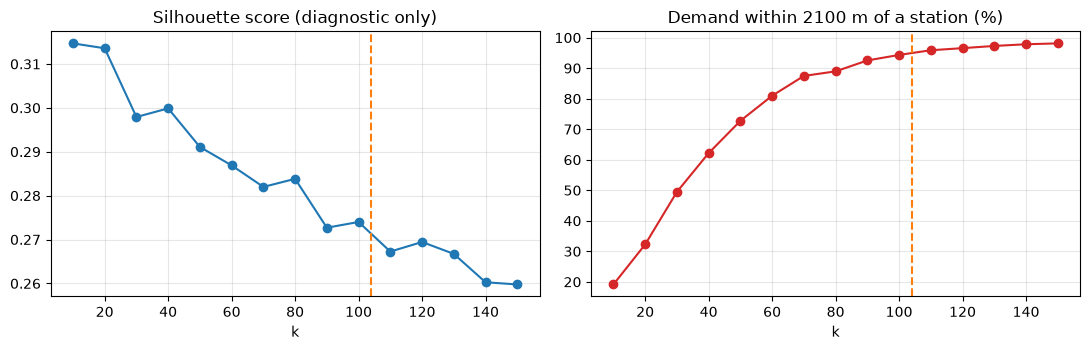

,k,silhouette,cov_2100m_pct
0,10,0.315,19.151
1,20,0.314,32.258
2,30,0.298,49.471
3,40,0.300,62.173
4,50,0.291,72.745
5,60,0.287,80.968
6,70,0.282,87.460
7,80,0.284,88.955
8,90,0.273,92.527
9,100,0.274,94.339


In [5]:
k = len(grid)
print(f"k = {k} (grid baseline: 3 km cells with >= 1% commercial/industrial land)")

rows = []
for kk in CFG["k_check_sweep"]:
    km = fit_weighted_kmeans(X, w, kk, CFG["seed"], 5, CFG["max_iter"])
    d = nearest_dist(X, km.cluster_centers_)
    rows.append({"k": kk, "silhouette": silhouette_score(X, km.labels_),
                 f"cov_{CFG['R_main_m']}m_pct": 100 * w[d <= CFG["R_main_m"]].sum() / w.sum()})
k_check = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(k_check["k"], k_check["silhouette"], marker="o"); axes[0].set_title("Silhouette score (diagnostic only)")
axes[1].plot(k_check["k"], k_check[f"cov_{CFG['R_main_m']}m_pct"], marker="o", color="tab:red")
axes[1].set_title(f"Demand within {CFG['R_main_m']} m of a station (%)")
for ax in axes:
    ax.axvline(k, color="tab:orange", ls="--"); ax.set_xlabel("k"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / "k_check.png", dpi=130); plt.show()
k_check.round(3)

## 5. From centres to stations

* **Move inside.** A centre is an average, so it can fall outside the study area (the NDMC/Cantonment hole
  or beyond the border). Such centres are moved to the nearest point inside the study area (`moved_in_area`).
* **Snap (variant).** Each centre is matched one-to-one to an OSM parking or fuel site within
  `snap_tolerance_m` (Hungarian assignment). OSM parking is undercounted, so this is a variant, not the main layout.

In [6]:
def build_stations(km, X, w, crs):
    c, lab = km.cluster_centers_, km.labels_
    st = gpd.GeoDataFrame({"station_id": np.arange(len(c)),
                           "cluster_demand": np.bincount(lab, weights=w, minlength=len(c)),
                           "n_points": np.bincount(lab, minlength=len(c)),
                           "raw_x": c[:, 0], "raw_y": c[:, 1]},
                          geometry=gpd.points_from_xy(c[:, 0], c[:, 1]), crs=crs)
    st["demand_share"] = st["cluster_demand"] / w.sum()
    return st


def move_inside(st, area, nudge_m=5.0):
    st = st.copy()
    inside = st.within(area)
    inner = area.buffer(-nudge_m)
    geoms = [g if ok else nearest_points(inner, g)[0] for g, ok in zip(st.geometry, inside)]
    st["moved_in_area"] = ~inside.to_numpy()
    st["move_m"] = [0.0 if ok else g.distance(n) for g, n, ok in zip(st.geometry, geoms, inside)]
    return st.set_geometry(gpd.GeoSeries(geoms, crs=st.crs))


def snap_to_sites(st, sites, tol_m):
    st = st.copy(); st["snapped"] = False; st["snap_dist_m"] = 0.0; st["snap_kind"] = None
    S, F = xy(st), xy(sites)
    dist = np.hypot(S[:, None, 0] - F[None, :, 0], S[:, None, 1] - F[None, :, 1])
    cost = np.where(dist <= tol_m, dist, 1e9)
    r, c = linear_sum_assignment(cost)
    ok = cost[r, c] < 1e9; r, c = r[ok], c[ok]
    nx, ny = S[:, 0].copy(), S[:, 1].copy(); nx[r], ny[r] = F[c, 0], F[c, 1]
    st = st.set_geometry(gpd.points_from_xy(nx, ny, crs=st.crs))
    st.loc[st.index[r], "snapped"] = True
    st.loc[st.index[r], "snap_dist_m"] = dist[r, c]
    st.loc[st.index[r], "snap_kind"] = sites["kind"].to_numpy()[c]
    return st


km_base = fit_weighted_kmeans(X, w, k, CFG["seed"], CFG["n_init"], CFG["max_iter"])
st = move_inside(build_stations(km_base, X, w, CRS), study_geom)
snapped = snap_to_sites(st, feasible, CFG["snap_tolerance_m"]) if CFG["snap_variant"] else None
print(f"k={k}: centres moved inside study area {int(st['moved_in_area'].sum())} (max {st['move_m'].max():.0f} m) | "
      f"snapped to OSM parking/fuel within {CFG['snap_tolerance_m']} m: {snapped['snapped'].mean():.0%}")

k=104: centres moved inside study area 0 (max 0 m) | snapped to OSM parking/fuel within 500 m: 29%


## 6. Evaluation (common metrics)

All layouts are scored on the same demand weights. Coverage = share of demand (or allocated population)
within R of the nearest station, straight-line.

In [7]:
rows = [evaluate_layout(X, w, xy(st), CFG["R_list_m"], f"kmeans (k={k})", pop)]
if snapped is not None:
    rows.append(evaluate_layout(X, w, xy(snapped), CFG["R_list_m"], f"kmeans (k={k}) snapped (variant)", pop))
rows += [evaluate_layout(X, w, xy(grid), CFG["R_list_m"], "grid baseline (3 km, 1%)", pop),
         evaluate_layout(X, w, xy(existing_4w), CFG["R_list_m"], "existing: confirmed 4W", pop),
         evaluate_layout(X, w, xy(existing_all), CFG["R_list_m"], "existing: all chargers", pop)]
summary = pd.DataFrame(rows).set_index("layout")
summary

,stations,mean_dist_m,median_dist_m,p95_dist_m,max_dist_m,cov_1000m_pct,cov_1500m_pct,cov_2100m_pct,cov_3000m_pct,pop_cov_2100m_pct
layout,,,,,,,,,,
kmeans (k=104),104,1145.1,1111.7,2075.4,5376.0,40.2,77.7,95.3,99.2,98.1
kmeans (k=104) snapped (variant),104,1158.4,1136.2,2096.9,5376.0,39.9,75.9,95.0,99.2,98.0
"grid baseline (3 km, 1%)",104,1456.8,1227.6,3018.7,9658.4,27.6,60.7,83.8,94.5,83.7
existing: confirmed 4W,98,2118.5,1554.0,6041.3,14033.2,29.1,48.7,64.8,78.6,68.9
existing: all chargers,1323,645.7,396.9,1972.3,10300.5,84.4,92.3,95.4,97.8,97.9


**Equity.** Population coverage within R by quintile of the ward's Scheduled Caste share (Q1 = lowest share).

In [8]:
demand["sc_q"] = pd.qcut(demand["sc_share"].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
eq = {}
for name, sxy in [(f"kmeans (k={k})", xy(st)), ("grid baseline", xy(grid)), ("existing 4W", xy(existing_4w))]:
    d = nearest_dist(X, sxy)
    cov = pd.Series(pop * (d <= CFG["R_main_m"])).groupby(demand["sc_q"], observed=True).sum() / \
          pd.Series(pop).groupby(demand["sc_q"], observed=True).sum()
    eq[name] = (100 * cov).round(1)
equity = pd.DataFrame(eq).T
equity.columns = [f"{c} pop cov {CFG['R_main_m']} m %" for c in equity.columns]
equity

,Q1 pop cov 2100 m %,Q2 pop cov 2100 m %,Q3 pop cov 2100 m %,Q4 pop cov 2100 m %,Q5 pop cov 2100 m %
kmeans (k=104),98.8,98.7,95.2,92.2,99.2
grid baseline,85.5,86.9,76.0,77.7,82.6
existing 4W,78.9,64.6,61.6,44.7,67.2


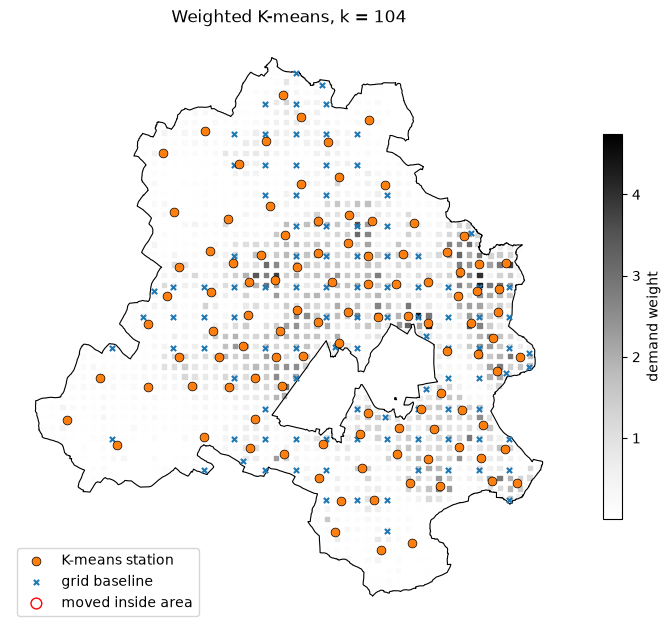

In [9]:
fig, ax = plt.subplots(figsize=(9, 10))
study.boundary.plot(ax=ax, color="black", lw=0.8)
scp = ax.scatter(X[:, 0], X[:, 1], c=w, s=10, cmap="Greys", marker="s")
ax.scatter(st.geometry.x, st.geometry.y, s=40, color="tab:orange", edgecolors="k", lw=0.5, label="K-means station", zorder=5)
ax.scatter(grid.geometry.x, grid.geometry.y, s=14, marker="x", color="tab:blue", label="grid baseline", zorder=4)
m = st["moved_in_area"]
ax.scatter(st[m].geometry.x, st[m].geometry.y, s=60, facecolors="none", edgecolors="red", label="moved inside area", zorder=6)
ax.set_title(f"Weighted K-means, k = {k}"); ax.legend(loc="lower left"); ax.set_aspect("equal"); ax.set_axis_off()
plt.colorbar(scp, ax=ax, shrink=0.5, label="demand weight")
plt.savefig(OUT / "stations_map.png", dpi=130, bbox_inches="tight"); plt.show()

## 7. Robustness

**7a. Seed stability.** K-means finds a local optimum; how far do stations move with a different random start?

In [10]:
srows = []
for s in range(1, CFG["n_seeds"] + 1):
    r = fit_weighted_kmeans(X, w, k, CFG["seed"] + s, CFG["n_init"], CFG["max_iter"])
    d = nearest_dist(km_base.cluster_centers_, r.cluster_centers_)
    srows.append(dict(seed=CFG["seed"] + s, inertia_vs_base_pct=100 * (r.inertia_ / km_base.inertia_ - 1),
                      median_shift_m=np.median(d), p90_shift_m=np.quantile(d, 0.9)))
stab = pd.DataFrame(srows)
stab[["inertia_vs_base_pct", "median_shift_m", "p90_shift_m"]].agg(["mean", "max"]).round(1)

,inertia_vs_base_pct,median_shift_m,p90_shift_m
mean,0.6,877.2,1769.6
max,1.1,964.9,1962.9


**7b. Monte Carlo persistence.** The weights rest on choices that cannot be estimated (no observed
charging data). Each run redraws them and refits:
* λ ~ Uniform(0.3, 0.8) (home vs destination share),
* θ (D and POI weights) ~ Dirichlet centred on the team's values (concentration 50),
* every weight × lognormal noise (σ = 0.3 in log space).

A base station **persists** in a run if the rerun has a station within 1 km (the brief's rule). Stations are
about 3.7 km apart at k = 104, so persistence within 2 km is also reported. Persistence ≥ 80% = robust site.
Each rerun layout is also scored on the base weights (coverage lost if the truth differs from the estimate).

**Control.** The same loop with unchanged weights and only a new random start shows how much movement is
K-means' own non-uniqueness (many near-equal optima on a smooth demand surface) rather than weight uncertainty.

In [11]:
def mc_persistence(perturb=True):
    """perturb=False: same weights, only the random start changes (control)."""
    rng = np.random.default_rng(CFG["seed"] + 1000)
    base_xy = xy(st)
    hit1, hit2, rows = np.zeros(len(base_xy)), np.zeros(len(base_xy)), []
    for i in range(CFG["mc_runs"]):
        if perturb:
            wp, par = dwmc.mc_weights(demand, rng, sigma=CFG["mc_sigma"], lam_range=CFG["mc_lam_range"],
                                      dirichlet_conc=CFG["mc_dirichlet_conc"])
        else:
            wp, par = w, {}
        km = fit_weighted_kmeans(X, wp, k, CFG["seed"] + i, max(3, CFG["n_init"] // 4), CFG["max_iter"])
        sxy = xy(move_inside(build_stations(km, X, wp, CRS), study_geom))
        dd = nearest_dist(base_xy, sxy)
        hit1 += dd <= CFG["persistence_delta_m"]; hit2 += dd <= 2000
        d = nearest_dist(X, sxy)
        rows.append(dict(run=i, perturbed=perturb, **par,
                         cov_main_on_base_w_pct=100 * w[d <= CFG["R_main_m"]].sum() / w.sum(),
                         mean_dist_on_base_w_m=np.average(d, weights=w)))
    n = CFG["mc_runs"]
    return pd.DataFrame(rows), hit1 / n, hit2 / n


mc_runs, p1, p2 = mc_persistence()
_, c1, c2 = mc_persistence(perturb=False)
st["persistence"], st["persistence_2km"], st["persistence_seed_only"] = p1, p2, c1
T = CFG["robust_threshold"]
st["robust"] = p1 >= T
persist = pd.DataFrame({"median persistence": [np.median(p1), np.median(p2), np.median(c1), np.median(c2)],
                        f"robust sites (>= {T:.0%})": [int((x >= T).sum()) for x in (p1, p2, c1, c2)]},
                       index=["MC (weights redrawn), within 1 km", "MC (weights redrawn), within 2 km",
                              "control (same weights), within 1 km", "control (same weights), within 2 km"])
cv = mc_runs["cov_main_on_base_w_pct"]
print(f"Coverage within {CFG['R_main_m']} m (on base weights) across {CFG['mc_runs']} MC layouts: "
      f"mean {cv.mean():.1f}%, min {cv.min():.1f}%, max {cv.max():.1f}%")
persist.round(2)

Coverage within 2100 m (on base weights) across 50 MC layouts: mean 94.5%, min 92.7%, max 95.9%


,median persistence,robust sites (>= 80%)
"MC (weights redrawn), within 1 km",0.57,17
"MC (weights redrawn), within 2 km",0.98,93
"control (same weights), within 1 km",0.59,31
"control (same weights), within 2 km",1.00,96


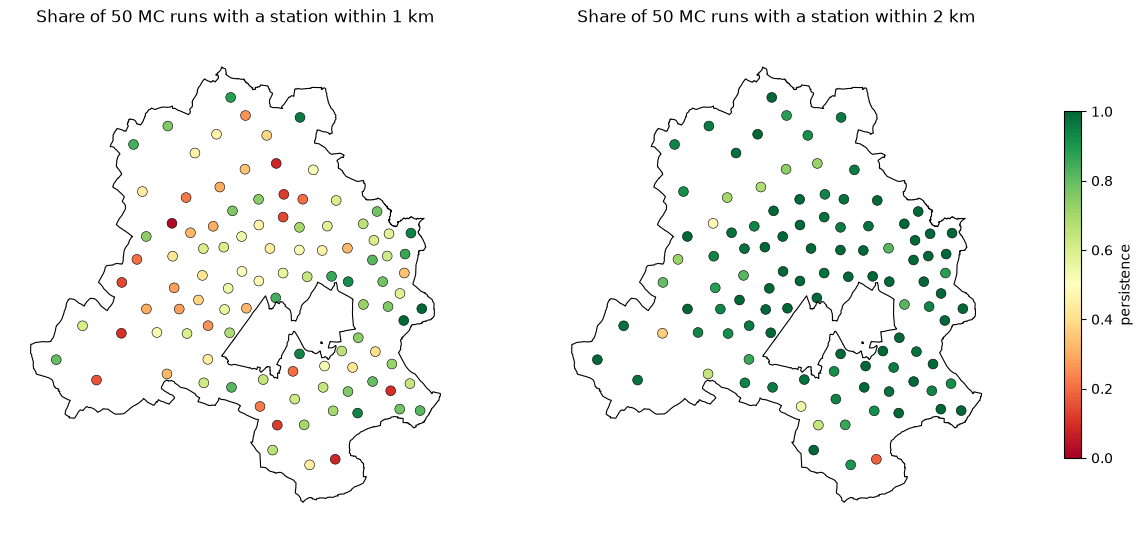

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9))
for ax, col, lab in [(axes[0], "persistence", "1 km"), (axes[1], "persistence_2km", "2 km")]:
    study.boundary.plot(ax=ax, color="black", lw=0.8)
    s_ = ax.scatter(st.geometry.x, st.geometry.y, c=st[col], cmap="RdYlGn", vmin=0, vmax=1, s=50, edgecolors="k", lw=0.4)
    ax.set_title(f"Share of {CFG['mc_runs']} MC runs with a station within {lab}")
    ax.set_aspect("equal"); ax.set_axis_off()
plt.colorbar(s_, ax=axes, shrink=0.5, label="persistence")
plt.savefig(OUT / "persistence_map.png", dpi=130, bbox_inches="tight"); plt.show()

## 8. Export

One row per station in the proposed common format (`method`, `scenario`, `budget`, `station_id`, `x`, `y`,
`lon`, `lat`, `cand_id`, `is_existing_fixed`) plus K-means extras.

In [13]:
out = st.copy()
out.insert(0, "method", "kmeans"); out.insert(1, "scenario", "A"); out.insert(2, "budget", k)
out["x"], out["y"] = out.geometry.x, out.geometry.y
ll = out.to_crs("EPSG:4326"); out["lon"], out["lat"] = ll.geometry.x, ll.geometry.y
out["cand_id"] = None; out["is_existing_fixed"] = False
tag = f"kmeans_A_k{k}"
out.drop(columns="geometry").to_csv(OUT / f"{tag}_stations.csv", index=False)
out.to_crs("EPSG:4326").to_file(OUT / f"{tag}_stations.geojson", driver="GeoJSON")

# GeoPackage for GIS (EPSG:32643, same CRS as the grid layers): stations + which station serves each demand cell
gpkg = OUT / f"{tag}.gpkg"
if gpkg.exists():
    gpkg.unlink()                                     # this notebook owns this file; rebuilt each run
out.drop(columns=["cand_id"]).to_file(gpkg, layer="kmeans_stations", driver="GPKG")
cells = gpd.read_file(CFG["demand_path"], layer="cells_polygons")[["cell_id", "geometry"]]
lab = pd.DataFrame({"cell_id": demand["cell_id"], "station_id": km_base.labels_, "weight": w})
cells.merge(lab, on="cell_id").to_file(gpkg, layer="kmeans_clusters", driver="GPKG")
if snapped is not None:
    snapped.to_file(gpkg, layer="kmeans_stations_snapped_variant", driver="GPKG")
print("GeoPackage:", gpkg)
if snapped is not None:
    snapped.drop(columns="geometry").assign(x=snapped.geometry.x, y=snapped.geometry.y) \
        .to_csv(OUT / f"{tag}_snapped_variant.csv", index=False)
summary.to_csv(OUT / "summary.csv"); equity.to_csv(OUT / "equity.csv"); k_check.to_csv(OUT / "k_check.csv", index=False)
stab.to_csv(OUT / "seed_stability.csv", index=False); mc_runs.to_csv(OUT / "mc_runs.csv", index=False)
persist.to_csv(OUT / "persistence_summary.csv")
print("Saved to", OUT)

GeoPackage: outputs/kmeans_v2/kmeans_A_k104.gpkg
Saved to outputs/kmeans_v2


## Assumptions and open items

* **k = 104** = the grid method's station count on the 2022 study area (D1), so all three methods use the same
  number of stations. The silhouette score is shown only as a diagnostic (no useful peak).
* Centres outside the study area are moved to the nearest point inside (5 m inward).
* Snapping to OSM parking/fuel is a variant only (OSM parking undercounted).
* Straight-line distances; coverage is scored on the new demand layer, which differs from the team's
  `demand_w` (`ev_4w_demand`). Scenario B (existing chargers as fixed centres) is not built yet.